In [9]:
import pandas as pd
import numpy as np
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
# 1. Load Data
train_std = pd.read_csv('D:/MK5 Project Sistem Cerdas/foodSaveProject/dataset/processed/catboost_train_standard.csv')
test_std = pd.read_csv('D:/MK5 Project Sistem Cerdas/foodSaveProject/dataset/processed/catboost_test_standard.csv')

X_train_std = train_std.drop(columns=['food_waste_kg'], errors='ignore')
y_train_std = train_std['food_waste_kg']
X_test_std = test_std.drop(columns=['food_waste_kg'], errors='ignore')
y_test_std = test_std['food_waste_kg']

# Deteksi otomatis kolom teks untuk CatBoost
cat_features_std = X_train_std.select_dtypes(include=['object']).columns.tolist()

# 2. Inisialisasi & Latih Model
model_std = CatBoostRegressor(iterations=500, learning_rate=0.1, depth=6, 
                              loss_function='RMSE', verbose=0, random_state=42)
model_std.fit(X_train_std, y_train_std, cat_features=cat_features_std)

# 3. Prediksi & Evaluasi
y_pred_std = model_std.predict(X_test_std)
mae_std = mean_absolute_error(y_test_std, y_pred_std)
rmse_std = np.sqrt(mean_squared_error(y_test_std, y_pred_std))
r2_std = r2_score(y_test_std, y_pred_std)

print("=== Hasil Eksperimen: STANDARD PREPROCESSING ===")
print(f"MAE       : {mae_std:.4f}")
print(f"RMSE      : {rmse_std:.4f}")
print(f"R² Score  : {r2_std:.4f}")

C:\Users\davew\AppData\Local\Temp\ipykernel_21584\348403105.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features_std = X_train_std.select_dtypes(include=['object']).columns.tolist()


=== Hasil Eksperimen: STANDARD PREPROCESSING ===
MAE       : 4.7660
RMSE      : 6.6777
R² Score  : 0.9315


In [11]:
# 1. Load Data
train_rob = pd.read_csv('D:/MK5 Project Sistem Cerdas/foodSaveProject/dataset/processed/catboost_train_robust.csv')
test_rob = pd.read_csv('D:/MK5 Project Sistem Cerdas/foodSaveProject/dataset/processed/catboost_test_robust.csv')

X_train_rob = train_rob.drop(columns=['food_waste_kg'], errors='ignore')
y_train_rob = train_rob['food_waste_kg']
X_test_rob = test_rob.drop(columns=['food_waste_kg'], errors='ignore')
y_test_rob = test_rob['food_waste_kg']

# Deteksi otomatis kolom teks untuk CatBoost
cat_features_rob = X_train_rob.select_dtypes(include=['object']).columns.tolist()

# 2. Inisialisasi & Latih Model
model_rob = CatBoostRegressor(iterations=500, learning_rate=0.1, depth=6, 
                              loss_function='RMSE', verbose=0, random_state=42)
model_rob.fit(X_train_rob, y_train_rob, cat_features=cat_features_rob)

# 3. Prediksi & Evaluasi
y_pred_rob = model_rob.predict(X_test_rob)
mae_rob = mean_absolute_error(y_test_rob, y_pred_rob)
rmse_rob = np.sqrt(mean_squared_error(y_test_rob, y_pred_rob))
r2_rob = r2_score(y_test_rob, y_pred_rob)

print("=== Hasil Eksperimen: ROBUST PREPROCESSING ===")
print(f"MAE       : {mae_rob:.4f}")
print(f"RMSE      : {rmse_rob:.4f}")
print(f"R² Score  : {r2_rob:.4f}")

C:\Users\davew\AppData\Local\Temp\ipykernel_21584\3501656215.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features_rob = X_train_rob.select_dtypes(include=['object']).columns.tolist()


=== Hasil Eksperimen: ROBUST PREPROCESSING ===
MAE       : 5.2048
RMSE      : 6.6136
R² Score  : 0.9328


In [12]:
print("=== KESIMPULAN PERBANDINGAN ===")
if mae_rob < mae_std:
    print(f"Robust Preprocessing LEBIH BAIK dari Standard (Selisih MAE: {mae_std - mae_rob:.4f})")
else:
    print(f"Standard Preprocessing LEBIH BAIK dari Robust (Selisih MAE: {mae_rob - mae_std:.4f})")

=== KESIMPULAN PERBANDINGAN ===
Standard Preprocessing LEBIH BAIK dari Robust (Selisih MAE: 0.4388)


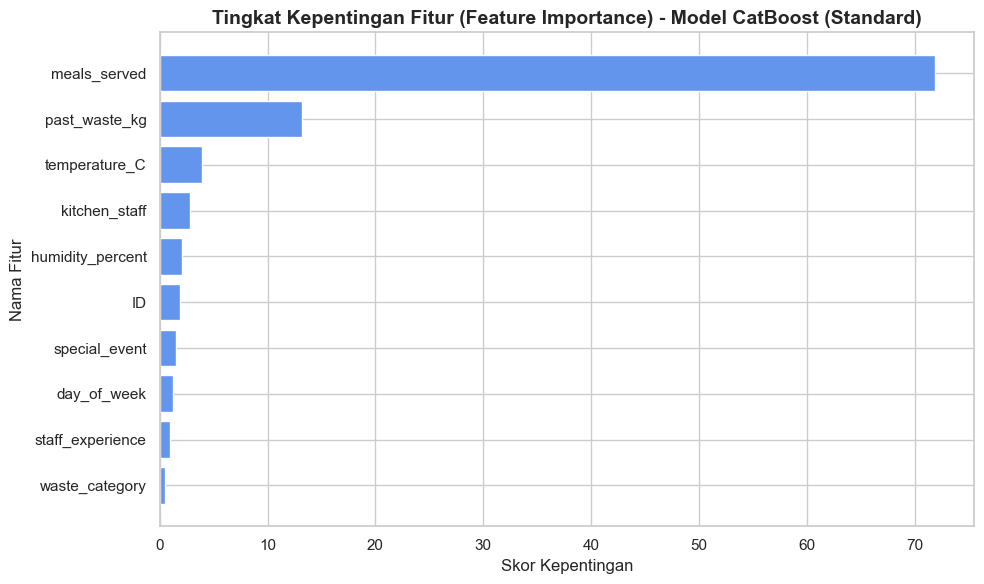

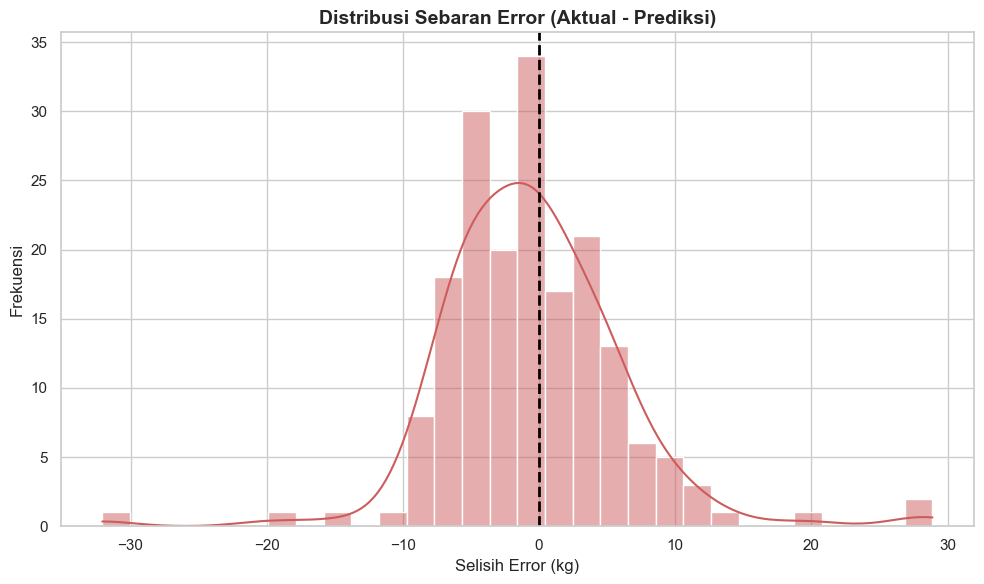

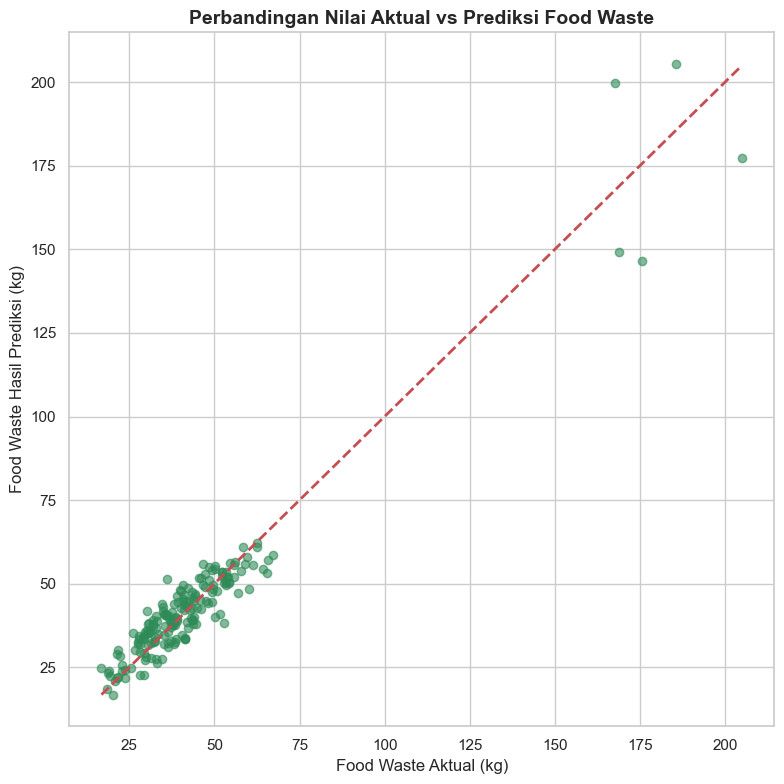

In [13]:
sns.set_theme(style="whitegrid")

# 1. VISUALISASI FEATURE IMPORTANCE
feature_importance = model_std.get_feature_importance()
sorted_idx = np.argsort(feature_importance)
fitur_terurut = np.array(X_train_std.columns)[sorted_idx]

plt.figure(figsize=(10, 6))
plt.barh(range(len(sorted_idx)), feature_importance[sorted_idx], align='center', color='cornflowerblue')
plt.yticks(range(len(sorted_idx)), fitur_terurut)
plt.title('Tingkat Kepentingan Fitur (Feature Importance) - Model CatBoost (Standard)', fontsize=14, fontweight='bold')
plt.xlabel('Skor Kepentingan', fontsize=12)
plt.ylabel('Nama Fitur', fontsize=12)
plt.tight_layout()
plt.show()

# 2. VISUALISASI SEBARAN ERROR
residuals = y_test_std - y_pred_std

plt.figure(figsize=(10, 6))
sns.histplot(residuals, kde=True, color='indianred', bins=30)
plt.axvline(x=0, color='black', linestyle='--', linewidth=2)
plt.title('Distribusi Sebaran Error (Aktual - Prediksi)', fontsize=14, fontweight='bold')
plt.xlabel('Selisih Error (kg)', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)
plt.tight_layout()
plt.show()

# 3. VISUALISASI AKTUAL VS PREDIKSI (SCATTER PLOT)
plt.figure(figsize=(8, 8))
plt.scatter(y_test_std, y_pred_std, alpha=0.6, color='seagreen')
# Membuat garis diagonal putus-putus sebagai patokan tebakan sempurna
plt.plot([y_test_std.min(), y_test_std.max()], [y_test_std.min(), y_test_std.max()], 'r--', linewidth=2)
plt.title('Perbandingan Nilai Aktual vs Prediksi Food Waste', fontsize=14, fontweight='bold')
plt.xlabel('Food Waste Aktual (kg)', fontsize=12)
plt.ylabel('Food Waste Hasil Prediksi (kg)', fontsize=12)
plt.tight_layout()
plt.show()